<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%BF%D1%80%D0%BE%D0%B4%D0%B2%D0%B8%D0%BD%D1%83%D1%82%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%964.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [1]:
%pip install -q ucimlrepo pymoo

import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from pymoo.core.problem import ElementwiseProblem
from pymoo.core.callback import Callback
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.moo.nsga3 import NSGA3
from pymoo.operators.sampling.rnd import BinaryRandomSampling
from pymoo.operators.crossover.pntx import TwoPointCrossover
from pymoo.operators.mutation.bitflip import BitflipMutation
from pymoo.optimize import minimize
from pymoo.indicators.hv import HV
from pymoo.util.ref_dirs import get_reference_directions

warnings.filterwarnings('ignore')

# Завдання 1. Дані та group-wise split

> Завантажити Parkinsons Telemonitoring Dataset і сформувати коректний subject-wise split.

In [ ]:
dataset = fetch_ucirepo(id=189)

X_all = dataset.data.features.copy()
targets = dataset.data.targets.copy()
ids = dataset.data.ids.copy()

print("Features shape:", X_all.shape)
print("Targets shape:", targets.shape)
print("IDs shape:", ids.shape)
print("\nFeatures:")
print(X_all.columns.tolist())
print("\nTargets:")
print(targets.columns.tolist())
print("\nIDs:")
print(ids.columns.tolist())
print("\nMissing values:", X_all.isna().sum().sum())

df = pd.concat([ids, X_all, targets], axis=1)

print(df.head())
print(df.describe().T)
print(df.groupby("subject#").size().describe())

Features shape: (5875, 19)
Targets shape: (5875, 2)
IDs shape: (5875, 1)

Features:
['age', 'test_time', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE', 'sex']

Targets:
['motor_UPDRS', 'total_UPDRS']

IDs:
['subject#']

Missing values: 0
   subject#  age  test_time  Jitter(%)  Jitter(Abs)  Jitter:RAP  Jitter:PPQ5  \
0         1   72     5.6431    0.00662     0.000034     0.00401      0.00317   
1         1   72    12.6660    0.00300     0.000017     0.00132      0.00150   
2         1   72    19.6810    0.00481     0.000025     0.00205      0.00208   
3         1   72    25.6470    0.00528     0.000027     0.00191      0.00264   
4         1   72    33.6420    0.00335     0.000020     0.00093      0.00130   

   Jitter:DDP  Shimmer  Shimmer(dB)  ...  Shimmer:APQ11  Shimmer:DDA  \
0     0.01204  0.02565        0.230  ...        0.01662    

Набір містить 5875 записів і 19 ознак без пропущених значень та дві цілі (`motor_UPDRS`, `total_UPDRS`). Ідентифікатор `subject#` в `ucimlrepo` лежить окремо в `data.ids`, а не серед `features`, тому для групування його додано до таблиці через `pd.concat`. Записів від 101 до 168 на пацієнта (у середньому близько 140), усього 42 пацієнти. Саме така структура зі багатьма повторними вимірюваннями одного суб'єкта створює ризик leakage при звичайному випадковому розбитті.

In [ ]:
target_col = "motor_UPDRS"
group_col = "subject#"

drop_cols = [
    "subject#",
    "age",
    "sex",
    "test_time",
    "motor_UPDRS",
    "total_UPDRS"
]

feature_cols = [c for c in df.columns if c not in drop_cols]

X = df[feature_cols].copy()
y = df[target_col].copy()
groups = df[group_col].copy()

print("Number of acoustic features:", len(feature_cols))
print(feature_cols)
print("Number of subjects:", groups.nunique())

Number of acoustic features: 16
['Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']
Number of subjects: 42


In [ ]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].reset_index(drop=True)
X_test = X.iloc[test_idx].reset_index(drop=True)

y_train = y.iloc[train_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)

g_train = groups.iloc[train_idx].reset_index(drop=True)
g_test = groups.iloc[test_idx].reset_index(drop=True)

print("Train subjects:", g_train.nunique())
print("Test subjects:", g_test.nunique())
print("Train records:", len(X_train), ", test records:", len(X_test))
print("Overlap:", set(g_train.unique()) & set(g_test.unique()))
print("motor_UPDRS train: mean", round(y_train.mean(), 2), ", std", round(y_train.std(), 2))
print("motor_UPDRS test: mean", round(y_test.mean(), 2), ", std", round(y_test.std(), 2))

Train subjects: 33
Test subjects: 9
Train records: 4640 , test records: 1235
Overlap: set()
motor_UPDRS train: mean 21.65 , std 8.22
motor_UPDRS test: mean 19.98 , std 7.64


Після видалення `subject#`, `age`, `sex`, `test_time` та обох UPDRS-змінних залишилось 16 акустичних ознак (5 ознак Jitter, 6 ознак Shimmer, а також NHR, HNR, RPDE, DFA і PPE). Розбиття `GroupShuffleSplit` дає 33 навчальних і 9 тестових суб'єктів (4640 і 1235 записів), перетин суб'єктів порожній, тобто протокол коректний. Розподіл цілі в train і test відрізняється: середнє `motor_UPDRS` 21.65 проти 19.98, std 8.22 проти 7.64. Тест містить лише 9 пацієнтів, тому його оцінки шумні.

# Завдання 2. Baseline Ridge Regression

> Побудувати baseline Ridge Regression на всіх акустичних ознаках.

In [ ]:
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

baseline.fit(X_train, y_train)
pred_base = baseline.predict(X_test)

base_rmse = mean_squared_error(y_test, pred_base) ** 0.5
base_mae = mean_absolute_error(y_test, pred_base)
base_r2 = r2_score(y_test, pred_base)

print("Baseline RMSE:", base_rmse)
print("Baseline MAE:", base_mae)
print("Baseline R2:", base_r2)
print("Number of features:", X_train.shape[1])

mean_pred = np.full(len(y_test), y_train.mean())
print("Constant (train mean) RMSE:", mean_squared_error(y_test, mean_pred) ** 0.5)
print("Constant (train mean) MAE:", mean_absolute_error(y_test, mean_pred))

Baseline RMSE: 8.71797994945057
Baseline MAE: 7.060538686828632
Baseline R2: -0.303544622367665
Number of features: 16
Constant (train mean) RMSE: 7.815368829395656
Constant (train mean) MAE: 6.906870374511379


Baseline Ridge на всіх 16 ознаках дає на нових суб'єктах RMSE 8.718, MAE 7.061 і R² = −0.304. Від'ємний R² означає, що модель прогнозує гірше, ніж просте середнє. Для контролю обчислено константний прогноз (середнє train): RMSE 7.815 і MAE 6.907, тобто baseline на всіх ознаках гірший за константу на 0.9 RMSE. Це важлива відправна точка: голосові ознаки самі по собі слабко пов'язані з `motor_UPDRS` на нових пацієнтах, і всі подальші покращення слід порівнювати з константним прогнозом (7.815), а не лише з baseline.

# Завдання 3. Двокритеріальна задача відбору ознак

> Реалізувати двокритеріальну задачу feature selection: CV RMSE + number of features.

In [ ]:
N_FEATURES = X_train.shape[1]
group_cv = GroupKFold(n_splits=5)

def grouped_cv_rmse(mask, alpha=1.0, cv_kind="group"):
    selected = np.where(mask)[0]

    if len(selected) == 0:
        return 1e6

    if cv_kind == "group":
        splits = group_cv.split(X_train, y_train, groups=g_train)
    else:
        splits = KFold(n_splits=5, shuffle=True, random_state=42).split(X_train, y_train)

    fold_rmse = []
    for tr_idx, val_idx in splits:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=alpha))
        ])

        model.fit(
            X_train.iloc[tr_idx, selected],
            y_train.iloc[tr_idx]
        )

        pred = model.predict(
            X_train.iloc[val_idx, selected]
        )

        rmse = mean_squared_error(
            y_train.iloc[val_idx],
            pred
        ) ** 0.5

        fold_rmse.append(rmse)

    return float(np.mean(fold_rmse))

class FeatureSelectionProblem(ElementwiseProblem):

    def __init__(self, alpha=1.0, cv_kind="group"):
        super().__init__(
            n_var=N_FEATURES,
            n_obj=2,
            n_ieq_constr=0,
            xl=0,
            xu=1,
            vtype=bool
        )
        self.alpha = alpha
        self.cv_kind = cv_kind

    def _evaluate(self, x, out, *args, **kwargs):
        mask = np.asarray(x, dtype=bool)

        if not mask.any():
            out["F"] = [1e6, N_FEATURES]
            return

        rmse = grouped_cv_rmse(mask, self.alpha, self.cv_kind)
        n_selected = int(mask.sum())

        out["F"] = [
            rmse,
            n_selected
        ]

problem = FeatureSelectionProblem()

all_mask = np.ones(N_FEATURES, dtype=bool)
t0 = time.time()
print("CV RMSE на всіх ознаках (GroupKFold):", grouped_cv_rmse(all_mask))
print("Час однієї оцінки, с:", time.time() - t0)
print("CV RMSE при порожній масці:", grouped_cv_rmse(np.zeros(N_FEATURES, dtype=bool)))

CV RMSE на всіх ознаках (GroupKFold): 8.634047814287882
Час однієї оцінки, с: 0.013446807861328125
CV RMSE при порожній масці: 1000000.0


Кожна оцінка маски коштує близько 0.012 с (5 фолдів Ridge), RMSE на всіх 16 ознаках за GroupKFold становить 8.634. Порожня маска в теорії штрафується значенням 1e6 за RMSE, але друга ціль у неї дорівнює нулю ознак, тому така маска за кількістю ознак найкраща і не домінується: у пробному запуску вона потрапляла на Pareto front. Щоб цього не було, у `FeatureSelectionProblem` для порожньої маски штрафуються обидві цілі (1e6 і максимальна кількість ознак). Це єдина відмінність від теорії в самій задачі; крім того, тип валідації та `alpha` винесено в параметри, щоб їх можна було змінювати в експериментах.

# Завдання 4. NSGA-II та Pareto front

> Запустити NSGA-II та побудувати Pareto front.

Number of Pareto solutions: 2
Кількість оцінок: 2400 , час, с: 23.1
 n_features  CV RMSE                     features
          1 8.045790                          PPE
          3 8.008683 Jitter(Abs), Jitter:RAP, PPE


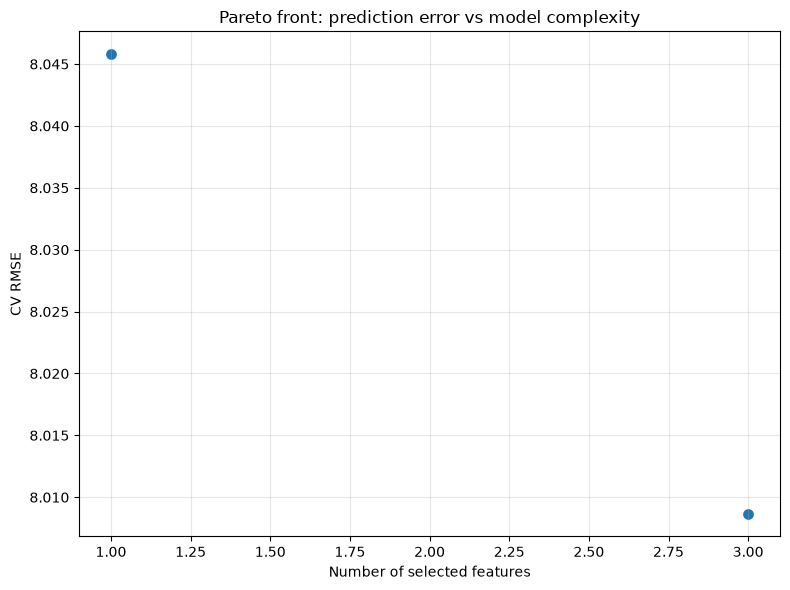

In [ ]:
algorithm = NSGA2(
    pop_size=60,
    sampling=BinaryRandomSampling(),
    crossover=TwoPointCrossover(prob=0.9),
    mutation=BitflipMutation(prob=1.0, prob_var=1.0 / N_FEATURES),
    eliminate_duplicates=True
)

start = time.time()
result = minimize(
    problem,
    algorithm,
    termination=("n_gen", 40),
    seed=42,
    verbose=False
)
main_time = time.time() - start

F = np.atleast_2d(result.F)
X_masks = np.atleast_2d(result.X)

print("Number of Pareto solutions:", len(F))
print("Кількість оцінок:", result.algorithm.evaluator.n_eval, ", час, с:", round(main_time, 1))

front_table = pd.DataFrame({
    "n_features": F[:, 1].astype(int),
    "CV RMSE": F[:, 0],
    "features": [", ".join(X_train.columns[np.asarray(m, dtype=bool)]) for m in X_masks]
}).sort_values("n_features")
print(front_table.to_string(index=False))

plt.figure(figsize=(8, 6))
plt.scatter(
    F[:, 1],
    F[:, 0],
    s=45
)
plt.xlabel("Number of selected features")
plt.ylabel("CV RMSE")
plt.title("Pareto front: prediction error vs model complexity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

NSGA-II з параметрами теорії (популяція 60, 40 поколінь, TwoPointCrossover 0.9, 2400 оцінок, 19.9 с) знайшов лише 2 Pareto-рішення: одну ознаку `PPE` із CV RMSE 8.0458 і три ознаки (`Jitter(Abs)`, `Jitter:RAP`, `PPE`) із CV RMSE 8.0087. Фронт малий, бо збільшення кількості ознак не знижує помилку за GroupKFold: на всіх 16 ознаках CV RMSE дорівнює 8.634, тобто значно вище. Додаткові ознаки погіршують узагальнення на нових суб'єктів, тому недомінованими є лише найкоротші підмножини. Мутацію задано як `prob=1.0, prob_var=1/N` (імовірність зміни кожного гена 1/N); у теорії стоїть `BitflipMutation(prob=1.0/N)`, що в pymoo є ймовірністю мутації особини, а не гена, тож це порівнюється в експерименті 3. Фронт малої розмірності не дозволяє аналізувати форму, тому подальші експерименти оцінюються також швидкістю досягнення цього фронту.

# Завдання 5. Вибір рішень із Pareto front

> Обрати most accurate, most compact та compromise solutions.

In [ ]:
rmse = F[:, 0]
nfeat = F[:, 1]

rmse_norm = (rmse - rmse.min()) / (rmse.max() - rmse.min() + 1e-12)
nfeat_norm = (nfeat - nfeat.min()) / (nfeat.max() - nfeat.min() + 1e-12)

distance = np.sqrt(rmse_norm**2 + nfeat_norm**2)
best_idx = np.argmin(distance)

compromise_mask = np.asarray(X_masks[best_idx], dtype=bool)
compromise_features = X_train.columns[compromise_mask].tolist()

print("Compromise CV RMSE:", F[best_idx, 0])
print("Selected features:", int(F[best_idx, 1]))
print(compromise_features)

idx_accuracy = np.argmin(F[:, 0])
idx_compact = np.argmin(F[:, 1])

candidate_indices = {
    "Most accurate": idx_accuracy,
    "Most compact": idx_compact,
    "Compromise": best_idx
}

for name, idx in candidate_indices.items():
    mask = np.asarray(X_masks[idx], dtype=bool)
    print(f"{name}: {int(F[idx, 1])} ознак, CV RMSE {F[idx, 0]:.4f}, {X_train.columns[mask].tolist()}")
print("Нормовані відстані до ідеальної точки:", np.round(distance, 3))

Compromise CV RMSE: 8.045789576419121
Selected features: 1
['PPE']
Most accurate: 3 ознак, CV RMSE 8.0087, ['Jitter(Abs)', 'Jitter:RAP', 'PPE']
Most compact: 1 ознак, CV RMSE 8.0458, ['PPE']
Compromise: 1 ознак, CV RMSE 8.0458, ['PPE']
Нормовані відстані до ідеальної точки: [1. 1.]


Most accurate: 3 ознаки (`Jitter(Abs)`, `Jitter:RAP`, `PPE`), CV RMSE 8.0087. Most compact: 1 ознака (`PPE`), CV RMSE 8.0458. Нормована відстань до ідеальної точки в обох точок однакова (1.0), оскільки на фронті лише дві точки і кожна дорівнює нулю в нормалізованій шкалі однієї цілі та одиниці в іншої, тому `argmin` вибирає першу точку (з однією ознакою). Тобто compromise збігається з most compact, і справжнього компромісу між трьома різними рішеннями на цьому фронті немає.

# Завдання 6. Оцінювання рішень на тестових суб'єктах

> Оцінити всі три рішення на незалежних test subjects.

               solution  n_features  cv_rmse  test_rmse  test_mae  test_r2
          Most accurate           3   8.0087     8.7328    7.3953  -0.3080
           Most compact           1   8.0458     7.7330    6.8267  -0.0256
             Compromise           1   8.0458     7.7330    6.8267  -0.0256
All features (baseline)          16   8.6340     8.7180    7.0605  -0.3035


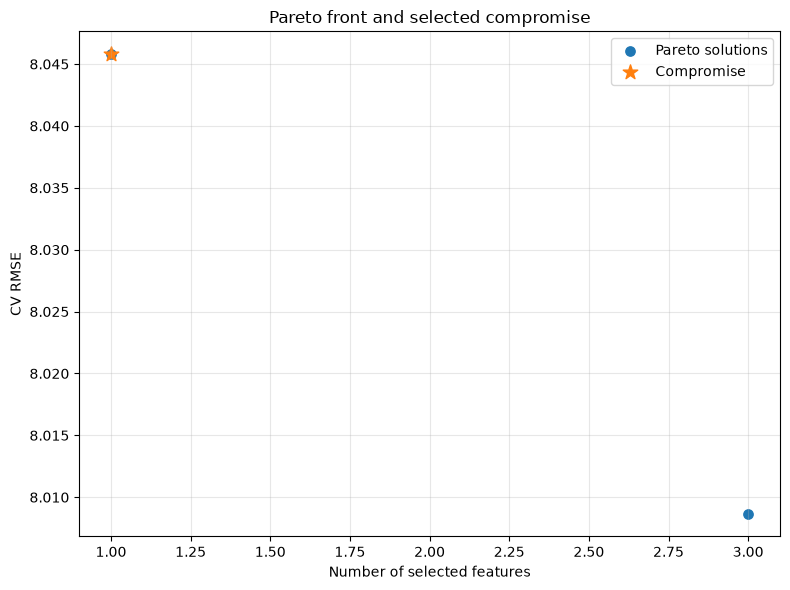

In [ ]:
rows = []

for name, idx in candidate_indices.items():
    mask = np.asarray(X_masks[idx], dtype=bool)
    cols = X_train.columns[mask].tolist()

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ])

    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])

    rows.append({
        "solution": name,
        "n_features": len(cols),
        "cv_rmse": F[idx, 0],
        "test_rmse": mean_squared_error(y_test, pred) ** 0.5,
        "test_mae": mean_absolute_error(y_test, pred),
        "test_r2": r2_score(y_test, pred)
    })

rows.append({
    "solution": "All features (baseline)",
    "n_features": N_FEATURES,
    "cv_rmse": grouped_cv_rmse(all_mask),
    "test_rmse": base_rmse,
    "test_mae": base_mae,
    "test_r2": base_r2
})

comparison = pd.DataFrame(rows)
print(comparison.round(4).to_string(index=False))

plt.figure(figsize=(8, 6))
plt.scatter(F[:, 1], F[:, 0], s=45, label="Pareto solutions")

plt.scatter(
    F[best_idx, 1],
    F[best_idx, 0],
    s=120,
    marker="*",
    label="Compromise"
)

plt.xlabel("Number of selected features")
plt.ylabel("CV RMSE")
plt.title("Pareto front and selected compromise")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

На 9 тестових суб'єктах рішення з однією ознакою `PPE` (most compact і compromise) дає RMSE 7.733, MAE 6.827, R² = −0.026, а most accurate за CV (3 ознаки) дає RMSE 8.733, MAE 7.395, R² = −0.308; baseline на 16 ознаках 8.718, константний прогноз 7.815. Різниця за CV між двома рішеннями мізерна (8.0458 проти 8.0087), а на тесті порядок змінюється, і різниця становить 1.0 RMSE, тобто рішення, найточніше за CV, не найкраще на нових суб'єктах. Рішення з `PPE` лише трохи кращий за константний прогноз (7.733 проти 7.815, різниця 0.08), R² усе ще від'ємний, тому голосові ознаки мало пояснюють `motor_UPDRS`. Усі висновки спираються на 9 тестових суб'єктів, тож їх варто сприймати як тенденцію.

# Завдання 7. Експерименти

> Провести всі експерименти з розділу 18.

> 1. Population size: 30; 60; 100. Що аналізувати: форма Pareto front, різноманіття, час.
> 2. Number of generations: 20; 40; 80. Що аналізувати: збіжність і стабільність фронту.
> 3. Mutation probability: 0.5/N; 1/N; 2/N. Що аналізувати: різноманіття розв'язків.
> 4. Ridge alpha: 0.1; 1; 10. Що аналізувати: чи змінюється Pareto front.
> 5. Повторні запуски: не менше 3 seeds. Що аналізувати: стабільність вибраних ознак.
> 6. GroupKFold vs звичайний KFold. Що аналізувати: оцінити ризик leakage.

In [ ]:
REF_POINT = np.array([9.0, 17.0])
hv_indicator = HV(ref_point=REF_POINT)

class HVCallback(Callback):

    def __init__(self):
        super().__init__()
        self.data["hv"] = []

    def notify(self, algorithm):
        self.data["hv"].append(float(hv_indicator(algorithm.opt.get("F"))))

def run_nsga(pop_size=60, n_gen=40, mutation_scale=1.0, alpha=1.0, cv_kind="group", seed=42, kind="nsga2"):
    start = time.time()
    if mutation_scale is None:
        mutation = BitflipMutation(prob=1.0 / N_FEATURES)
    else:
        mutation = BitflipMutation(prob=1.0, prob_var=mutation_scale / N_FEATURES)
    common = dict(
        sampling=BinaryRandomSampling(),
        crossover=TwoPointCrossover(prob=0.9),
        mutation=mutation,
        eliminate_duplicates=True
    )
    if kind == "nsga2":
        algo = NSGA2(pop_size=pop_size, **common)
    else:
        ref_dirs = get_reference_directions("das-dennis", 2, n_partitions=pop_size - 1)
        algo = NSGA3(pop_size=pop_size, ref_dirs=ref_dirs, **common)
    res = minimize(
        FeatureSelectionProblem(alpha, cv_kind), algo,
        termination=("n_gen", n_gen), seed=seed, verbose=False, callback=HVCallback()
    )
    Fr = np.atleast_2d(res.F)
    Xr = np.atleast_2d(res.X).astype(bool)
    return {"F": Fr, "X": Xr, "time": time.time() - start, "hv_history": res.algorithm.callback.data["hv"],
            "n_eval": res.algorithm.evaluator.n_eval, "seed": seed}

def compromise_index(Fr):
    r = (Fr[:, 0] - Fr[:, 0].min()) / (Fr[:, 0].max() - Fr[:, 0].min() + 1e-12)
    k = (Fr[:, 1] - Fr[:, 1].min()) / (Fr[:, 1].max() - Fr[:, 1].min() + 1e-12)
    return int(np.argmin(np.sqrt(r**2 + k**2)))

def run_summary(run):
    Fr = run["F"]
    unique = np.unique(Fr.round(6), axis=0)
    i = int(np.argmin(Fr[:, 0]))
    return {
        "розв'язків": len(Fr),
        "унікальних точок": len(unique),
        "min CV RMSE": float(Fr[:, 0].min()),
        "ознак при min": int(Fr[i, 1]),
        "HV": float(hv_indicator(Fr)),
        "покоління до повного HV": int(np.argmax(np.array(run["hv_history"]) >= run["hv_history"][-1] - 1e-9)) + 1,
        "час, с": run["time"]
    }

def aggregate_runs(runs):
    table = pd.DataFrame([run_summary(r) for r in runs])
    return {c: f"{table[c].mean():.4f} ± {table[c].std(ddof=0):.4f}" if c in ("min CV RMSE", "HV") else f"{table[c].mean():.1f} ± {table[c].std(ddof=0):.1f}" for c in table.columns}

def plot_fronts(runs_by_name, title):
    plt.figure(figsize=(8, 5))
    for name, runs in runs_by_name.items():
        Fr = runs[0]["F"]
        order = np.argsort(Fr[:, 1])
        plt.step(Fr[order, 1], Fr[order, 0], where="post", marker="o", label=name)
    plt.xlabel("Number of selected features")
    plt.ylabel("CV RMSE")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

SEEDS = [0, 1, 2, 3, 4]
base_runs = [run_nsga(seed=s) for s in SEEDS]
print("Базова конфігурація (pop 60, 40 поколінь, mutation 1/N, alpha 1), 5 seeds")
print(pd.DataFrame([run_summary(r) for r in base_runs], index=[f"seed {s}" for s in SEEDS]).round(4).to_string())

Базова конфігурація (pop 60, 40 поколінь, mutation 1/N, alpha 1), 5 seeds
        розв'язків  унікальних точок  min CV RMSE  ознак при min       HV  покоління до повного HV   час, с
seed 0           2                 2       8.0087              3  15.7869                       11  20.9314
seed 1           2                 2       8.0087              3  15.7869                       10  20.7560
seed 2           2                 2       8.0087              3  15.7869                        8  20.7490
seed 3           2                 2       8.0087              3  15.7869                        6  20.8733
seed 4           2                 2       8.0087              3  15.7869                       11  20.7703


Для експериментів визначено допоміжні функції. Кожен запуск порівнюється за кількістю розв'язків на фронті, мінімальним CV RMSE, hypervolume (HV, опорна точка (9.0, 17), тобто більше значення означає кращий фронт), часом і номером покоління, з якого HV досягає свого фінального значення (швидкість збіжності). Для експериментів 1–4 використано 3 seeds (0, 1, 2), а для експерименту 5 і базової конфігурації 5 seeds. Базова конфігурація на всіх 5 seeds дає той самий фронт із двох точок (HV 15.7869), а повне значення HV досягається на 6–11 поколінні.

# Експеримент 1. Population size

    розв'язків унікальних точок      min CV RMSE ознак при min                HV покоління до повного HV      час, с
30   2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000              10.7 ± 3.8  10.4 ± 0.1
60   2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000               9.7 ± 1.2  20.8 ± 0.1
100  2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000               7.7 ± 1.2  35.1 ± 0.1


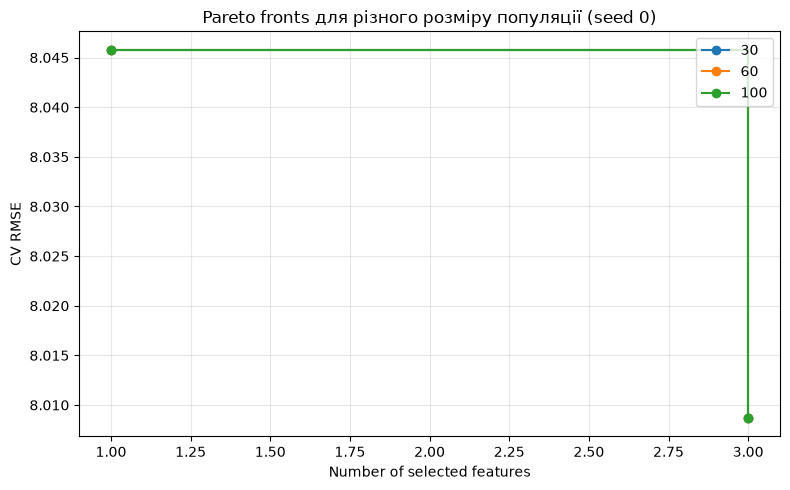

In [ ]:
exp1_runs = {"30": [run_nsga(pop_size=30, seed=s) for s in SEEDS[:3]],
             "60": base_runs[:3],
             "100": [run_nsga(pop_size=100, seed=s) for s in SEEDS[:3]]}
print(pd.DataFrame({k: aggregate_runs(v) for k, v in exp1_runs.items()}).T.to_string())
plot_fronts(exp1_runs, "Pareto fronts для різного розміру популяції (seed 0)")

У всіх трьох варіантах (30, 60, 100 особин) фронт однаковий: 2 розв'язки, мінімум CV RMSE 8.0087, HV 15.7869. Розмір популяції впливає лише на ціну: час 10.4, 20.8 і 35.1 с, тобто приблизно пропорційний кількості оцінок, а покоління до повного HV: 10.7 ± 3.8, 9.7 ± 1.2 і 7.7 ± 1.2 (більша популяція збігається трохи швидше за кількістю поколінь, але не за часом). Оскільки простір має лише 2^16 масок, а фронт складається з двох точок, навіть популяція 30 його знаходить. Різноманіття вздовж фронту оцінити неможливо, бо фронт містить два розв'язки.

# Експеримент 2. Number of generations

   розв'язків унікальних точок      min CV RMSE ознак при min                HV покоління до повного HV      час, с
20  2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000               9.7 ± 1.2  10.5 ± 0.0
40  2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000               9.7 ± 1.2  20.8 ± 0.1
80  2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000               9.7 ± 1.2  41.7 ± 0.1


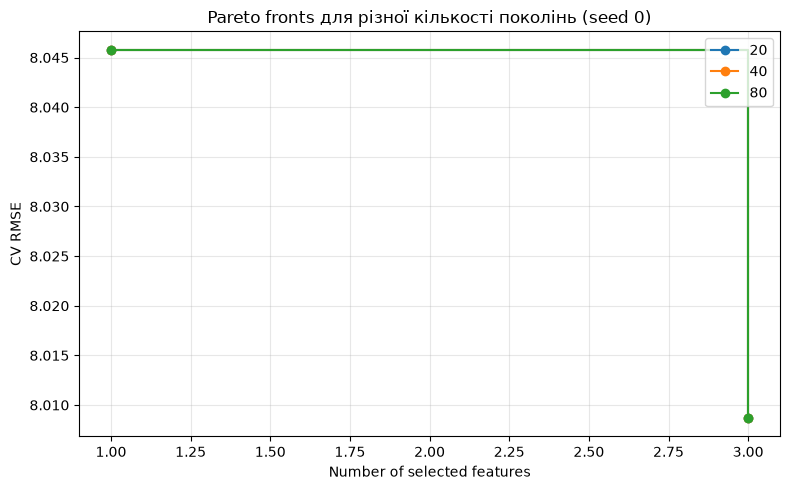

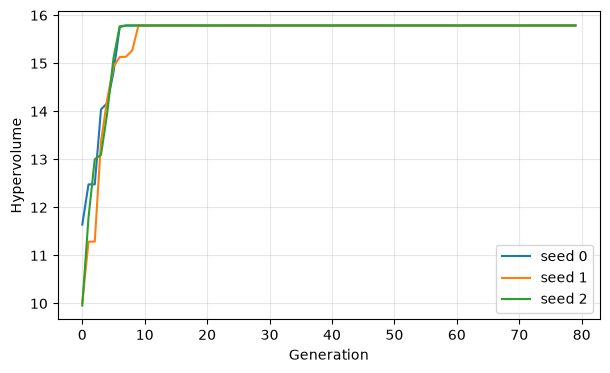

HV на поколіннях 5, 10, 20, 40, 80 (середнє за seeds): [14.1312 15.7867 15.7869 15.7869 15.7869]


In [ ]:
exp2_runs = {"20": [run_nsga(n_gen=20, seed=s) for s in SEEDS[:3]],
             "40": base_runs[:3],
             "80": [run_nsga(n_gen=80, seed=s) for s in SEEDS[:3]]}
print(pd.DataFrame({k: aggregate_runs(v) for k, v in exp2_runs.items()}).T.to_string())
plot_fronts(exp2_runs, "Pareto fronts для різної кількості поколінь (seed 0)")

plt.figure(figsize=(7, 4))
for s in SEEDS[:3]:
    plt.plot(exp2_runs["80"][s]["hv_history"], label=f"seed {s}")
plt.xlabel("Generation")
plt.ylabel("Hypervolume")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
hv_curves = np.array([r["hv_history"] for r in exp2_runs["80"]])
print("HV на поколіннях 5, 10, 20, 40, 80 (середнє за seeds):", hv_curves.mean(axis=0)[[4, 9, 19, 39, 79]].round(4))

Фронт для 20, 40 і 80 поколінь той самий (2 розв'язки, HV 15.7869), а час зростає лінійно (10.5, 20.8 і 41.7 с). HV на п'ятому поколінні в середньому 14.13, на десятому 15.7867, на двадцятому вже остаточні 15.7869, тобто алгоритм збігається приблизно за 10 поколінь (у середньому 9.7 ± 1.2). Криві HV для різних seeds відрізняються лише першими поколіннями, а фінальний фронт однаковий. Тому 20 поколінь достатньо, а 80 лише подвоює час без користі.

# Експеримент 3. Mutation probability

                         розв'язків унікальних точок      min CV RMSE ознак при min                HV покоління до повного HV      час, с
0.5/N                     2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000               9.0 ± 2.4  20.8 ± 0.0
1/N                       2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000               9.7 ± 1.2  20.8 ± 0.1
2/N                       2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000              17.3 ± 6.6  22.2 ± 1.4
prob = 1/N (як у теорії)  2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000               9.3 ± 3.3  20.9 ± 0.1


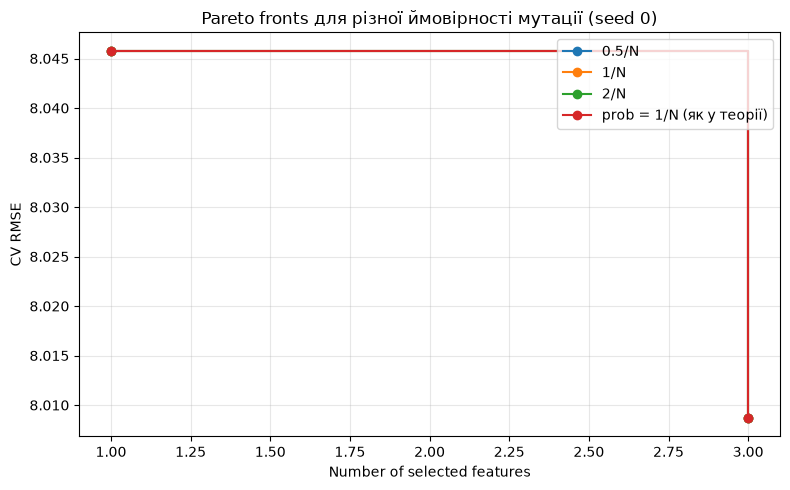

In [ ]:
exp3_runs = {"0.5/N": [run_nsga(mutation_scale=0.5, seed=s) for s in SEEDS[:3]],
             "1/N": base_runs[:3],
             "2/N": [run_nsga(mutation_scale=2.0, seed=s) for s in SEEDS[:3]],
             "prob = 1/N (як у теорії)": [run_nsga(mutation_scale=None, seed=s) for s in SEEDS[:3]]}
print(pd.DataFrame({k: aggregate_runs(v) for k, v in exp3_runs.items()}).T.to_string())
plot_fronts(exp3_runs, "Pareto fronts для різної ймовірності мутації (seed 0)")

Для 0.5/N, 1/N і 2/N фронт однаковий (2 розв'язки, HV 15.7869), але швидкість збіжності відрізняється: покоління до повного HV 9.0 ± 2.4, 9.7 ± 1.2 і 17.3 ± 6.6, тобто висока ймовірність мутації (2/N) уповільнює збіжність приблизно вдвічі. Варіант за теорією (`prob=1/N`: мутує приблизно кожна 16-та особина, і в ній кожен ген з імовірністю за замовчуванням 1/16) дає той самий фронт і збіжність 9.3 ± 3.3, тож для такого малого простору вибір оператора мутації майже не має значення: фронт знаходять початкова популяція та схрещування. Різноманіття розв'язків (кількість унікальних точок) в усіх варіантах дорівнює 2.

# Експеримент 4. Ridge alpha

    розв'язків унікальних точок      min CV RMSE ознак при min                HV покоління до повного HV      час, с
0.1  2.0 ± 0.0        2.0 ± 0.0  8.0092 ± 0.0000     3.0 ± 0.0  15.7789 ± 0.0000               7.3 ± 1.2  20.8 ± 0.0
1    2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000               9.7 ± 1.2  20.8 ± 0.1
10   2.0 ± 0.0        2.0 ± 0.0  8.0034 ± 0.0000     3.0 ± 0.0  15.8620 ± 0.0000              10.0 ± 1.4  20.9 ± 0.1


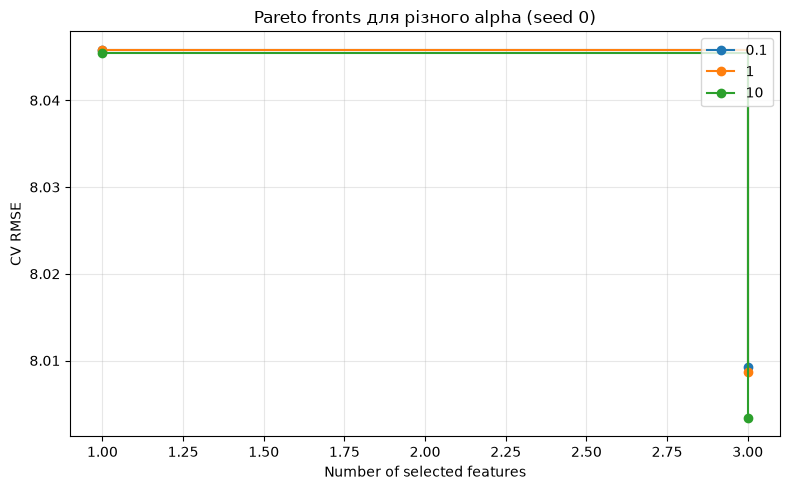

alpha = 0.1: CV RMSE на всіх ознаках = 8.6396
alpha = 1.0: CV RMSE на всіх ознаках = 8.634
alpha = 10.0: CV RMSE на всіх ознаках = 8.5943


In [ ]:
exp4_runs = {"0.1": [run_nsga(alpha=0.1, seed=s) for s in SEEDS[:3]],
             "1": base_runs[:3],
             "10": [run_nsga(alpha=10.0, seed=s) for s in SEEDS[:3]]}
print(pd.DataFrame({k: aggregate_runs(v) for k, v in exp4_runs.items()}).T.to_string())
plot_fronts(exp4_runs, "Pareto fronts для різного alpha (seed 0)")

for alpha in [0.1, 1.0, 10.0]:
    print(f"alpha = {alpha}: CV RMSE на всіх ознаках =", round(grouped_cv_rmse(all_mask, alpha=alpha), 4))

При alpha 0.1, 1 і 10 фронт складається з двох розв'язків із трьома ознаками при мінімумі, але значення зсуваються: мінімальний CV RMSE 8.0092, 8.0087 і 8.0034, HV 15.7789, 15.7869 і 15.8620 (HV змінюється, бо змінюються самі значення RMSE, а не форма фронту). RMSE на всіх 16 ознаках також зменшується із зростанням alpha: 8.640, 8.634 і 8.594. Тобто сильніша регуляризація трохи покращує узагальнення, але різниці порядку 0.005 і менше, а кількість розв'язків на фронті та кількість ознак при мінімумі не змінюються.

# Експеримент 5. Повторні запуски

In [ ]:
selected_feature_lists = []
rows = []
for r in base_runs:
    i = compromise_index(r["F"])
    cols = X_train.columns[r["X"][i]].tolist()
    selected_feature_lists.append(cols)
    rows.append({"seed": r["seed"], "розв'язків": len(r["F"]), "compromise: ознак": len(cols),
                 "compromise CV RMSE": r["F"][i, 0], "ознаки": ", ".join(cols)})
print(pd.DataFrame(rows).set_index("seed").round(4).to_string())
print("Агреговано за 5 seeds:", aggregate_runs(base_runs))

      розв'язків  compromise: ознак  compromise CV RMSE ознаки
seed                                                          
0              2                  1              8.0458    PPE
1              2                  1              8.0458    PPE
2              2                  1              8.0458    PPE
3              2                  1              8.0458    PPE
4              2                  1              8.0458    PPE
Агреговано за 5 seeds: {"розв'язків": '2.0 ± 0.0', 'унікальних точок': '2.0 ± 0.0', 'min CV RMSE': '8.0087 ± 0.0000', 'ознак при min': '3.0 ± 0.0', 'HV': '15.7869 ± 0.0000', 'покоління до повного HV': '9.2 ± 1.9', 'час, с': '20.8 ± 0.1'}


Усі 5 seeds дають однаковий фронт із двох розв'язків, а compromise завжди складається з однієї ознаки `PPE` (CV RMSE 8.0458). Стабільність повна: розкид метрик між запусками нульовий, а відрізняється лише швидкість збіжності (6–11 поколінь).

# Завдання 8. GroupKFold та випадковий KFold

> Окремо порівняти GroupKFold із випадковим KFold та пояснити різницю.

Це також експеримент 6 із розділу 18.

In [ ]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
overlap = []
for tr_idx, val_idx in kfold.split(X_train):
    val_subjects = set(g_train.iloc[val_idx])
    train_subjects = set(g_train.iloc[tr_idx])
    overlap.append(len(val_subjects & train_subjects) / len(val_subjects))
print("Частка суб'єктів валідації, що є і в train (KFold) по фолдах:", np.round(overlap, 3))

group_overlap = []
for tr_idx, val_idx in group_cv.split(X_train, y_train, groups=g_train):
    group_overlap.append(len(set(g_train.iloc[val_idx]) & set(g_train.iloc[tr_idx])))
print("Перетин суб'єктів (GroupKFold) по фолдах:", group_overlap)

print("\nBaseline (всі ознаки, Ridge alpha = 1):")
print("  CV RMSE GroupKFold:", round(grouped_cv_rmse(all_mask, cv_kind="group"), 4))
print("  CV RMSE KFold:", round(grouped_cv_rmse(all_mask, cv_kind="kfold"), 4))
print("  Test RMSE (нові суб'єкти):", round(base_rmse, 4))

Частка суб'єктів валідації, що є і в train (KFold) по фолдах: [1. 1. 1. 1. 1.]
Перетин суб'єктів (GroupKFold) по фолдах: [0, 0, 0, 0, 0]

Baseline (всі ознаки, Ridge alpha = 1):
  CV RMSE GroupKFold: 8.634
  CV RMSE KFold: 7.7237
  Test RMSE (нові суб'єкти): 8.718


У випадковому KFold усі суб'єкти валідаційної частини присутні й у навчальній (частка 1.0 в кожному з 5 фолдів), тоді як GroupKFold дає нульовий перетин. Наслідок: для baseline на всіх ознаках CV RMSE за KFold 7.724, за GroupKFold 8.634, а на нових суб'єктах 8.718. Тобто KFold занижує помилку приблизно на 0.9 (модель частково розпізнає знайомих пацієнтів), а GroupKFold близький до реальної якості на нових суб'єктах (8.634 проти 8.718).

In [ ]:
kfold_runs = [run_nsga(cv_kind="kfold", seed=s) for s in SEEDS[:3]]

rows = []
for kind, runs in [("GroupKFold", base_runs[:3]), ("KFold", kfold_runs)]:
    for r in runs:
        i = compromise_index(r["F"])
        cols = X_train.columns[r["X"][i]].tolist()
        idx_cols = np.where(r["X"][i])[0]
        model = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]).fit(X_train[cols], y_train)
        test_rmse = mean_squared_error(y_test, model.predict(X_test[cols])) ** 0.5
        rows.append({
            "CV у цілі": kind, "seed": r["seed"], "розв'язків": len(r["F"]), "ознак": len(cols),
            "CV RMSE (у цілі)": r["F"][i, 0],
            "GroupKFold RMSE цієї підмножини": grouped_cv_rmse(r["X"][i], cv_kind="group"),
            "Test RMSE": test_rmse
        })
leak = pd.DataFrame(rows)
print(leak.round(4).to_string(index=False))
front_kf = kfold_runs[0]
order = np.argsort(front_kf["F"][:, 1])
print(pd.DataFrame({
    "n_features": front_kf["F"][order, 1].astype(int),
    "KFold CV RMSE": front_kf["F"][order, 0],
    "GroupKFold RMSE": [grouped_cv_rmse(m, cv_kind="group") for m in front_kf["X"][order]]
}).round(4).to_string(index=False))
print(leak.groupby("CV у цілі")[["ознак", "CV RMSE (у цілі)", "GroupKFold RMSE цієї підмножини", "Test RMSE"]].mean().round(4).to_string())

 CV у цілі  seed  розв'язків  ознак  CV RMSE (у цілі)  GroupKFold RMSE цієї підмножини  Test RMSE
GroupKFold     0           2      1            8.0458                           8.0458      7.733
GroupKFold     1           2      1            8.0458                           8.0458      7.733
GroupKFold     2           2      1            8.0458                           8.0458      7.733
     KFold     0          12      4            7.8310                           8.0737      8.359
     KFold     1          12      4            7.8310                           8.0737      8.359
     KFold     2          12      4            7.8310                           8.0737      8.359
 n_features  KFold CV RMSE  GroupKFold RMSE
          1         8.1153           8.0458
          2         8.0037           8.1028
          3         7.9008           8.0087
          4         7.8310           8.0737
          5         7.8073           8.1121
          6         7.7541           8.2320
      

Якщо NSGA-II оптимізує KFold RMSE, фронт значно багатший (12 розв'язків проти 2): KFold винагороджує додаткові ознаки, і RMSE монотонно знижується з 8.115 (1 ознака) до 7.723 (12 ознак), бо ознаки допомагають розпізнавати пацієнтів. Для тих самих підмножин GroupKFold RMSE змінюється в протилежному напрямку: 8.046 для 1 ознаки і 8.351 для 12. Compromise, вибраний за KFold (4 ознаки), має KFold RMSE 7.831 (оптимістично), GroupKFold RMSE 8.074 і RMSE на нових тестових суб'єктах 8.359, тоді як compromise із GroupKFold (одна ознака `PPE`) дає 7.733. Тобто leakage призводить до вибору більшої кількості ознак і гіршого результату на нових суб'єктах. Результати однакові для всіх трьох seeds.

# Завдання 9. Стабільність відбору ознак

> Для кількох seeds дослідити стабільність вибраних ознак.

PPE              5
Jitter(%)        0
Jitter(Abs)      0
Jitter:RAP       0
Jitter:PPQ5      0
Jitter:DDP       0
Shimmer          0
Shimmer(dB)      0
Shimmer:APQ3     0
Shimmer:APQ5     0
Shimmer:APQ11    0
Shimmer:DDA      0
NHR              0
HNR              0
RPDE             0
DFA              0
dtype: int64


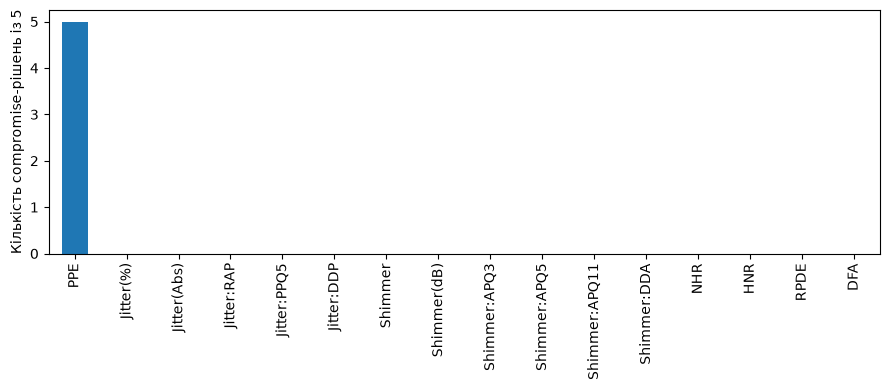

Пари ознак із |r| > 0.95: 14 з 120
[('Jitter:RAP', 'Jitter:DDP', np.float64(1.0)), ('Shimmer', 'Shimmer(dB)', np.float64(0.993)), ('Shimmer:APQ3', 'Shimmer:DDA', np.float64(1.0))]
Частота ознак серед усіх розв'язків фронтів: {'PPE': 10, 'Jitter(Abs)': 5, 'Jitter:RAP': 5}


In [ ]:
counter = Counter(
    feature
    for features in selected_feature_lists
    for feature in features
)
frequency = pd.Series(counter).reindex(feature_cols).fillna(0).astype(int).sort_values(ascending=False)
print(frequency)

frequency.plot(kind="bar", figsize=(9, 4))
plt.ylabel("Кількість compromise-рішень із 5")
plt.tight_layout()
plt.show()

corr = X_train.corr().abs()
pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(feature_cols) for b in feature_cols[i + 1:] if corr.loc[a, b] > 0.95]
print("Пари ознак із |r| > 0.95:", len(pairs), "з", len(feature_cols) * (len(feature_cols) - 1) // 2)
print([p for p in pairs if p[2] > 0.99])

all_front_features = Counter()
for r in base_runs:
    for m in r["X"]:
        all_front_features.update(X_train.columns[m].tolist())
print("Частота ознак серед усіх розв'язків фронтів:", dict(sorted(all_front_features.items(), key=lambda kv: -kv[1])))

Із 5 seeds ознака `PPE` входить до compromise-рішення в 5 випадках із 5, а решта 15 ознак жодного разу, тобто вибір повністю стабільний. Серед усіх розв'язків фронтів `PPE` зустрічається 10 разів (в обох точках кожного запуску), `Jitter(Abs)` і `Jitter:RAP` по 5 разів (лише в рішенні з трьома ознаками). Стабільність така висока, бо в усіх запусках знайдено той самий фронт. Слід враховувати кореляцію: 14 із 120 пар ознак мають |r| > 0.95, а пари `Jitter:RAP`/`Jitter:DDP` та `Shimmer:APQ3`/`Shimmer:DDA` мають r = 1.0 (практично дублюють одна одну), тому вибір `Jitter:RAP`, а не `Jitter:DDP`, не має змістовного пояснення і ознаки в таких парах взаємозамінні. Стабільність вибору `PPE` свідчить, що вона є найкориснішою з 16 ознак для групової валідації, але не доводить, що вона добре прогнозує `motor_UPDRS`.

# Завдання 10. Вибір рішення для практичної системи

> Сформулювати, яке Pareto-рішення ви обрали б для практичної системи і чому.

Я обрав би рішення з однією ознакою `PPE` (most compact і compromise). По-перше, воно найпростіше та найдешевше. По-друге, воно практично не поступається за CV RMSE (8.0458 проти 8.0087 для трьох ознак), а на нових тестових суб'єктах краще (7.733 проти 8.733). По-третє, воно стабільне: усі 5 seeds і обидва алгоритми знаходять його, а решта ознак групової валідації лише шкодить. Але застереження суттєве: його RMSE лише на 0.08 нижчий за константний прогноз (7.815), а R² на тесті від'ємний (−0.026), тобто навіть ця модель практично не прогнозує `motor_UPDRS` на нових пацієнтах. Тому як практичну систему її можна вважати лише початковою точкою, а не готовим інструментом, і потрібна перевірка на більшій кількості пацієнтів.

# Додаткове завдання підвищеної складності

> Оберіть один варіант: (1) додайте третю ціль — inference time або model complexity; (2) замініть Ridge на нелінійну модель та порівняйте Pareto fronts; (3) використайте NSGA-III або інший multi-objective optimizer; (4) побудуйте knee-point selection іншим методом та порівняйте вибір із normalized-distance approach.

Обрано варіант (3): NSGA-III із тими самими операторами, розміром популяції та кількістю поколінь, що й у базовому NSGA-II.

         розв'язків унікальних точок      min CV RMSE ознак при min                HV покоління до повного HV      час, с
NSGA-II   2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000               9.7 ± 1.2  20.8 ± 0.1
NSGA-III  2.0 ± 0.0        2.0 ± 0.0  8.0087 ± 0.0000     3.0 ± 0.0  15.7869 ± 0.0000              12.3 ± 1.9  21.2 ± 0.1
      NSGA-II  NSGA-III  спільних масок  min RMSE NSGA-II  min RMSE NSGA-III
seed                                                                        
0           2         2               2            8.0087             8.0087
1           2         2               2            8.0087             8.0087
2           2         2               2            8.0087             8.0087


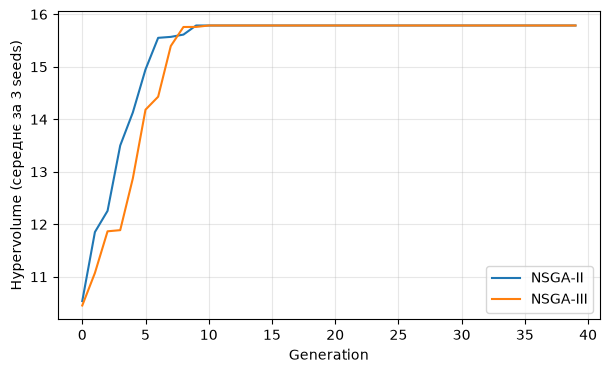

In [ ]:
nsga3_runs = [run_nsga(kind="nsga3", seed=s) for s in SEEDS[:3]]

print(pd.DataFrame({"NSGA-II": aggregate_runs(base_runs[:3]), "NSGA-III": aggregate_runs(nsga3_runs)}).T.to_string())

rows = []
for a, b in zip(base_runs[:3], nsga3_runs):
    set_a = {tuple(m) for m in a["X"]}
    set_b = {tuple(m) for m in b["X"]}
    rows.append({"seed": a["seed"], "NSGA-II": len(set_a), "NSGA-III": len(set_b), "спільних масок": len(set_a & set_b),
                 "min RMSE NSGA-II": a["F"][:, 0].min(), "min RMSE NSGA-III": b["F"][:, 0].min()})
print(pd.DataFrame(rows).set_index("seed").round(4).to_string())

plt.figure(figsize=(7, 4))
plt.plot(np.mean([r["hv_history"] for r in base_runs[:3]], axis=0), label="NSGA-II")
plt.plot(np.mean([r["hv_history"] for r in nsga3_runs], axis=0), label="NSGA-III")
plt.xlabel("Generation")
plt.ylabel("Hypervolume (середнє за 3 seeds)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

NSGA-III із тими самими операторами, популяцією 60 і 40 поколіннями дає той самий фронт: 2 розв'язки, ті самі маски (2 спільні з NSGA-II для кожного seed), мінімум CV RMSE 8.0087 і HV 15.7869. Час практично однаковий (21.2 проти 20.8 с), а повного HV NSGA-III досягає трохи пізніше (12.3 ± 1.9 проти 9.7 ± 1.2 покоління). Тобто для двох цілей і фронту з двох точок два алгоритми не розрізняються, а різниця в швидкості збіжності невелика й порівнянна з розкидом між seeds. NSGA-III розрахований на задачі з багатьма цілями, і переваги такого підходу в двокритеріальній задачі проявитися не можуть.

# Висновки

У цьому практикумі ми навчились формулювати відбір ознак як двокритеріальну задачу (CV RMSE і кількість ознак), використовувати NSGA-II для пошуку множини недомінованих рішень, будувати Pareto front, вибирати компромісні рішення та правильно працювати з повторними вимірюваннями одного пацієнта за допомогою group-wise split. Метою роботи було ознайомитися з багатокритеріальною оптимізацією та алгоритмом NSGA-II, сформулювати відбір ознак як одночасну оптимізацію помилки та кількості ознак, побудувати Pareto front, проаналізувати компромісні рішення та перевірити вибраний розв'язок на незалежних суб'єктах, і її досягнуто.

**Результати.** Baseline Ridge на 16 ознаках дає RMSE 8.718 на 9 нових суб'єктах (R² = −0.304), що гірше за константний прогноз 7.815. NSGA-II знаходить Pareto front із двох точок: `PPE` (1 ознака, CV RMSE 8.0458) і `Jitter(Abs)`, `Jitter:RAP`, `PPE` (3 ознаки, 8.0087). Рішення з однією ознакою (також compromise) має на тесті RMSE 7.733 проти 8.733 для рішення з трьома ознаками. Це рішення збігається в усіх 5 seeds, і NSGA-III дає той самий фронт. Розмір популяції, кількість поколінь, ймовірність мутації та alpha не змінюють структуру фронту; вони впливають лише на час і швидкість збіжності (приблизно 10 поколінь достатньо, висока мутація 2/N збіжність уповільнює). Випадковий KFold занижує помилку (7.724 проти 8.634 для GroupKFold і 8.718 на тесті) і призводить до вибору більшої кількості ознак (фронт із 12 точок) та гіршого результату на нових суб'єктах (8.359 проти 7.733).

**Обмеження.** Фронт містить лише дві точки, тому compromise збігається з most compact, а аналіз різноманіття розв'язків обмежений. Тест складається з 9 суб'єктів, а виграш найкращого рішення над константним прогнозом дуже малий (0.08 RMSE при R² < 0), тому відібрані голосові ознаки слабко прогнозують `motor_UPDRS`, і результат придатний лише як ілюстрація методу.

# Контрольні питання

**1. Чим багатокритеріальна оптимізація відрізняється від однокритеріальної?**

В однокритеріальній оптимізації є одна цільова функція, наприклад мінімізація RMSE, і результатом є один розв'язок. У багатокритеріальній потрібно одночасно враховувати кілька, зазвичай суперечливих, критеріїв, наприклад помилку прогнозу та кількість ознак. Тому результатом є не один розв'язок, а множина компромісних розв'язків, з якої потім потрібно вибрати один за додатковими міркуваннями.

**2. Що означає Pareto dominance?**

Розв'язок A домінує розв'язок B, якщо A не гірший за B за всіма критеріями і кращий щонайменше за одним. Розв'язок, який не домінується жодним іншим, називається Pareto-optimal.

**3. Що таке Pareto front?**

Pareto front це образ множини Pareto-optimal розв'язків у просторі цілей, тобто набір значень (CV RMSE, кількість ознак) недомінованих розв'язків. Ліва частина фронту відповідає компактнішим моделям, нижня точнішим, і якщо дві точки мають однакову кількість ознак, гірша за RMSE до фронту не входить.

**4. Чому в цій задачі немає одного об'єктивно найкращого розв'язку?**

Цілі суперечать одна одній: модель із більшою кількістю ознак може мати меншу помилку, але є складнішою, дорожчою та менш інтерпретованою, а модель із меншою кількістю ознак простіша, але може бути менш точною. Жодна точка фронту не краща за інші за обома критеріями одночасно, тому вибір залежить від того, яку вагу надають кожному з критеріїв.

**5. Для чого NSGA-II використовує non-dominated sorting?**

Non-dominated sorting розподіляє популяцію за рівнями Pareto dominance: перший фронт складається з недомінованих розв'язків, другий з тих, що домінуються лише розв'язками першого, і так далі. Це дає алгоритму спосіб порівнювати індивідів за кількома цілями без зведення їх до одного числа та віддавати перевагу кращим фронтам при відборі.

**6. Яку роль відіграє crowding distance?**

Crowding distance вимірює, наскільки щільно розв'язки розташовані навколо даного розв'язку в межах одного фронту. Під час відбору перевага віддається розв'язкам із більшою відстанню, тобто з менш заселених ділянок, що зберігає різноманіття вздовж Pareto front і не дає популяції зібратися в одній точці.

**7. Чому кількість ознак є окремою ціллю, а не просто технічною деталлю?**

Кількість ознак визначає складність, вартість і інтерпретованість моделі, а модель із 5 ознаками може бути простішою, дешевшою та зрозумілішою за модель із 16, навіть якщо помилка в неї трохи більша. Якщо вважати це технічною деталлю й оптимізувати лише RMSE, компроміс між простотою та точністю залишиться прихованим, а як окрема ціль він стає видимим у вигляді Pareto front.

**8. Чому для Parkinsons Telemonitoring потрібен group-wise split?**

Кожен пацієнт має багато повторних записів, тому при звичайному випадковому розбитті записи одного й того самого суб'єкта потрапляють і в train, і в test, і модель може запам'ятовувати особливості конкретних пацієнтів, а не загальну залежність. Це призводить до data leakage й завищеної оцінки якості, тому зовнішній test set формується за GroupShuffleSplit, а objective function усередині NSGA-II оцінюється за GroupKFold.

**9. Чим compromise solution відрізняється від most accurate solution?**

Most accurate solution це точка фронту з найменшою помилкою, незалежно від кількості ознак. Compromise solution обирається як точка з мінімальною відстанню до ідеальної точки (0, 0) у нормалізованому просторі двох цілей, тобто враховує одночасно і помилку, і кількість ознак, і зазвичай використовує менше ознак ціною дещо більшої помилки.

**10. Чому стабільність набору вибраних ознак важлива для наукової інтерпретації?**

Якщо набір ознак значно змінюється між запусками, це свідчить, що вибір залежить від випадкових чинників, а не від справжньої інформативності. Тому ознаки, які входять до compromise-рішень стабільно, можна вважати інформативними, а ті, що з'являються лише в окремих запусках, швидше випадкові.